# Cross-community Method Adoption
## tl;dr
Across three held-out medical-imaging periods, exposure counts, collaboration-community breadth
and directed citation paths show no consistent incremental predictive benefit. The primary
analysis contains 202 pair-period rows and 32 events. No added mechanism passes the declared
top-20 improvement gate. The backtest reconstructs history with current metadata.

## Context & Methods
Robotics fixes extraction rules and model settings before medical outcomes are inspected.
Medical feature origins are end-2019, end-2021 and end-2023; outcomes occupy the next 24 months.
Only previously completed windows enter each refit. Every model uses the declared C=0.2
ridge-logistic fallback because the development training split has only six primary events.

The primary risk set has one to ten prior asserted method/task-use papers. A sustained event
requires three pairwise author-disjoint future papers without seed authors, with qualifying
papers in two six-month bins. Each term has at least twenty past corpus papers.

### Key Assumptions
The fixed ontology, use-assertion heuristic, resolved authors and corpus-restricted communities
are measurement proxies. Positive precision has only an AI development review; recall and
medical-domain precision remain unmeasured. Current abstracts and identities are not verified
historical records. Repeated pairs and overlapping methods create dependent observations.

This notebook reads committed aggregate results and predictions. Exact raw replication also
requires the ignored snapshots identified in `results/execution_manifest.json`. See the
adjacent `protocol.md`, `ledger.md` and `findings.md` for the study decisions and sources.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score, brier_score_loss

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "research/adoption").is_dir())
OUT = ROOT / "research/adoption/results"
metrics = pd.read_csv(OUT / "evaluation.csv")
predictions = pd.read_csv(OUT / "predictions.csv")
increments = pd.read_csv(OUT / "comparisons.csv")
primary = metrics[(metrics.risk == "weak") & (metrics.target == "event")]
stages = ["temporal", "static", "exposure", "breadth", "undirected", "directed", "reverse"]
labels = ["History + context", "Static relationships", "Exposure counts", "Exposure breadth",
          "Undirected paths", "Directed paths", "Reversed paths"]
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

## Data
OpenAlex acquisition and preparation counts; full abstracts are excluded from this notebook.

In [2]:
acquisition = json.loads((OUT / "medical_acquisition.json").read_text())
audit = json.loads((OUT / "medical_audit.json").read_text())
display(pd.Series({"Acquired records": acquisition["records"],
                   "Retained records": audit["records"],
                   "Missing references": audit["missing_references"],
                   "Missing authors": audit["missing_authors"]}, name="Papers").to_frame())
assert audit["records"] + sum(audit["exclusions"].values()) == acquisition["records"]
display(primary[primary.stage == "temporal"][["origin", "n", "events", "prevalence"]].round(3))

,Papers
Acquired records,89619
Retained records,86022
Missing references,21533
Missing authors,1754


,origin,n,events,prevalence
0,2019-12-31,48,12,0.250
104,2021-12-31,69,8,0.116
208,2023-12-31,85,12,0.141


## Results
### Average Precision
Feature sets are cumulative. Directed and reversed models each retain undirected features.

origin,2019-12-31,2021-12-31,2023-12-31
stage,,,
temporal,0.786,0.625,0.364
static,0.806,0.632,0.361
exposure,0.759,0.633,0.359
breadth,0.772,0.650,0.355
undirected,0.801,0.650,0.350
directed,0.801,0.582,0.353
reverse,0.801,0.657,0.351


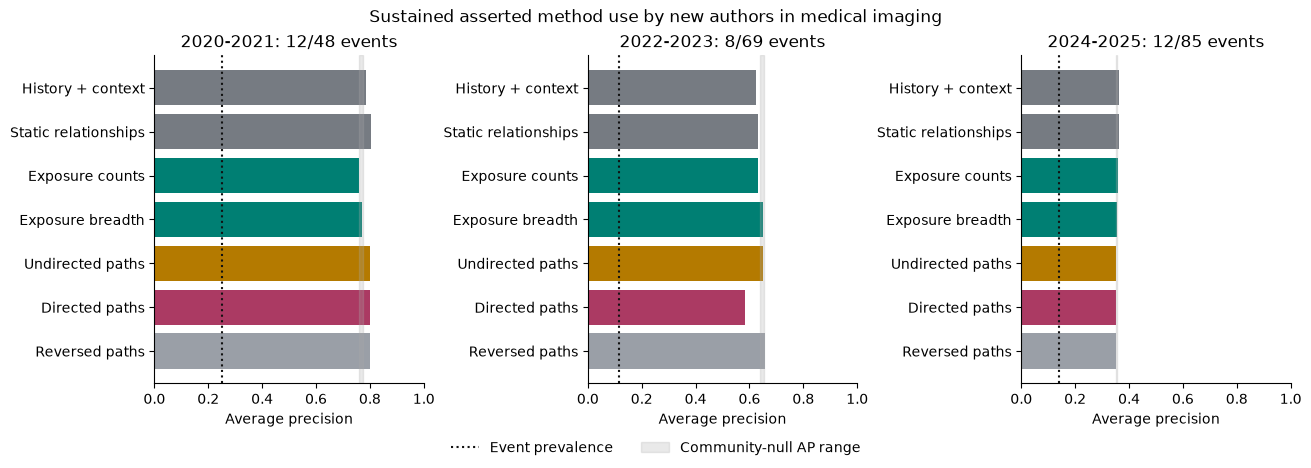

In [3]:
display(primary[primary.stage.isin(stages)].pivot(index="stage", columns="origin", values="ap")
        .reindex(stages).round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), layout="constrained")
for ax, (origin, group) in zip(axes, primary.groupby("origin")):
    values = group.set_index("stage").reindex(stages)
    ax.barh(range(7), values.ap, color=["#767b82", "#767b82", "#007f73", "#007f73",
                                       "#b47a00", "#ab3a63", "#9a9fa7"])
    ax.axvline(values.prevalence.iloc[0], color="#111111", ls=":", label="Event prevalence")
    nulls = group[group.stage.str.startswith("null_")].ap
    ax.axvspan(nulls.min(), nulls.max(), color="#aaaaaa", alpha=.25,
               label="Community-null AP range")
    year = int(origin[:4])
    ax.set_title(f"{year+1}-{year+2}: {int(values.events.iloc[0])}/{int(values.n.iloc[0])} events")
    ax.set_yticks(range(7), labels)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Average precision")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("Sustained asserted method use by new authors in medical imaging", fontsize=12)
plt.show()

### Incremental Performance
The bounds below are 2.5th-97.5th percentiles of 500 method/application identity-weight draws,
with fitted predictions held fixed. They describe ontology-composition sensitivity.
Population sampling, model refitting and metadata uncertainty are outside these bounds.
All primary ranges include zero.

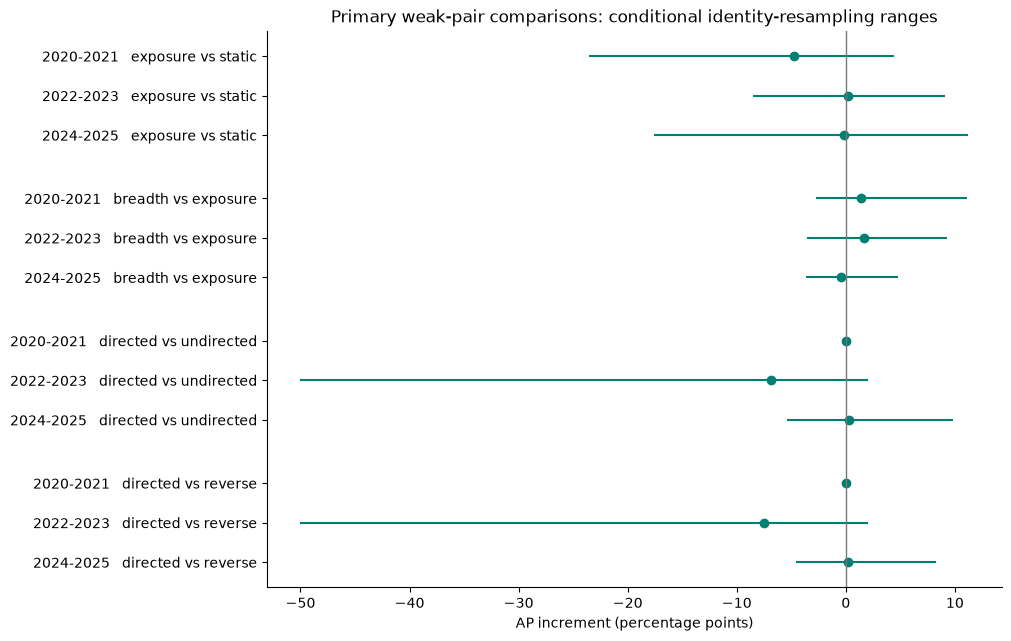

In [4]:
part = increments[increments.risk == "weak"]
fig, ax = plt.subplots(figsize=(10, 6.3), layout="constrained")
offset, ticks, names = 0, [], []
for (baseline, stage), group in part.groupby(["baseline", "stage"], sort=False):
    for row in group.itertuples():
        ax.hlines(offset, row.resampling_low_pp, row.resampling_high_pp, color="#007f73")
        ax.plot(row.delta_ap_pp, offset, "o", color="#007f73")
        year = int(row.origin[:4])
        ticks.append(offset)
        names.append(f"{year+1}-{year+2}   {stage} vs {baseline}")
        offset += 1
    offset += .6
ax.set_yticks(ticks, names)
ax.axvline(0, color="#777777", lw=1)
ax.invert_yaxis()
ax.set_xlabel("AP increment (percentage points)")
ax.set_title("Primary weak-pair comparisons: conditional identity-resampling ranges")
plt.show()

### Review Budget
Correct events among the twenty highest-ranked candidates. Ties use saved candidate order.

In [5]:
top20 = primary[primary.stage.isin(stages)].pivot(index="stage", columns="origin", values="p20")
display((20 * top20.reindex(stages)).round().astype(int))
exposure_null = primary[primary.stage.str.startswith("null_")].groupby("origin").ap.agg(["min", "max"])
display(exposure_null.round(3))

origin,2019-12-31,2021-12-31,2023-12-31
stage,,,
temporal,12,7,8
static,12,8,7
exposure,12,8,7
breadth,11,8,6
undirected,12,8,7
directed,12,8,6
reverse,12,8,6


,min,max
origin,,
2019-12-31,0.759,0.775
2021-12-31,0.639,0.656
2023-12-31,0.352,0.356


Breadth supplies no additional top-budget event in any period; the final period loses one
relative to exposure counts. Its AP lies inside the activity-stratified community-null range
in each period. Directed paths supply no stable advantage over the direction controls.

### Sensitivities and Checks
Zero-prior-use pairs have one, zero and one sustained events. The event-free period has
undefined AP. Excluding seed authors' prior collaborators leaves 10, 8 and 11 events.
The secondary endpoints reuse primary rankings; their probabilities are not separately
calibrated forecasts. Matching finds no admissible high/low-breadth pair in any period.

In [6]:
display(metrics[(metrics.stage == "temporal") & (metrics.target == "event") & (metrics.risk == "zero")]
        [["origin", "n", "events", "ap"]].round(3))
checked = 0
for (origin, stage), group in predictions.groupby(["origin", "stage"]):
    for risk in ["weak", "zero"]:
        rows = group[group.prior > 0] if risk == "weak" else group[group.prior == 0]
        expected = metrics[(metrics.origin == origin) & (metrics.stage == stage)
                           & (metrics.risk == risk) & (metrics.target == "event")].iloc[0]
        if rows.event.sum():
            assert np.isclose(average_precision_score(rows.event, rows.probability), expected.ap)
        assert np.isclose(brier_score_loss(rows.event, rows.probability), expected.brier)
        checked += 1
assert checked == 102
validation = json.loads((OUT / "validation.json").read_text())
display(pd.Series({"Saved metric groups recomputed": checked,
                   "Feature rows checked": validation["feature_row_checks"],
                   "Author/date witnesses checked": validation["witness_checks"]}).to_frame("Checks"))

,origin,n,events,ap
3,2019-12-31,68,1,0.077
107,2021-12-31,98,0,NaN
211,2023-12-31,109,1,1.000


,Checks
Saved metric groups recomputed,102
Feature rows checked,477
Author/date witnesses checked,15


## Takeaways
The tested feature sets fail the practical improvement gate. The evidence supports stopping
network-model expansion on this pilot. It leaves broader propagation hypotheses unresolved.
An additional study needs independently adjudicated use relations and earliest-public text
before further predictive claims.

The version audit extracts fourteen of sixteen first-version abstracts, with twelve plain-alias
and nine assertion-rule agreements. Disagreements include transport and heuristic effects;
they do not establish five actual text revisions. Historical author/reference identities remain
unverified. The prospective ledger has no completed outcomes: its window is
2026-10-16 through 2028-10-15, with no later evaluation scheduled.

Prior art: [Ugander et al. (2012)](https://doi.org/10.1073/pnas.1116502109),
[Aral et al. (2009)](https://pmc.ncbi.nlm.nih.gov/articles/PMC2799846/).
The source filter, hashes and individual arXiv v1 URLs are in the committed result manifests.